# Timeseries examples

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

In [2]:
df = pd.read_csv("glenmore_traffic.csv")
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 70080 entries, 0 to 70079
Data columns (total 3 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   DIRECTION   70080 non-null  str  
 1   STUDY_DATE  70080 non-null  str  
 2   VOLUME      70080 non-null  int64
dtypes: int64(1), str(2)
memory usage: 1.6 MB

In [3]:
# convert the study date to datetime for plotting
df["STUDY_DATE"] = pd.to_datetime(df["STUDY_DATE"], format=r"%m/%d/%Y %I:%M:%S %p")

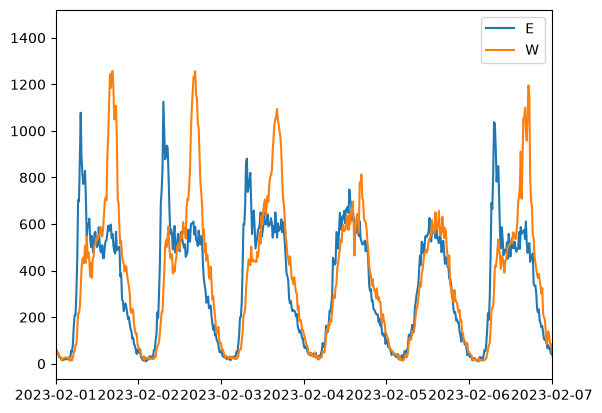

In [7]:
for dir in ["E", "W"]:
    this_dir = df[df["DIRECTION"] == dir]
    plt.plot(this_dir["STUDY_DATE"], this_dir["VOLUME"], label=dir)

plt.legend()
# zoom in so we can see a bit more detail
plt.xlim(pd.to_datetime(["2023-02-01", "2023-02-7"]))

array([[1.        , 0.93789682],
       [0.93789682, 1.        ]])

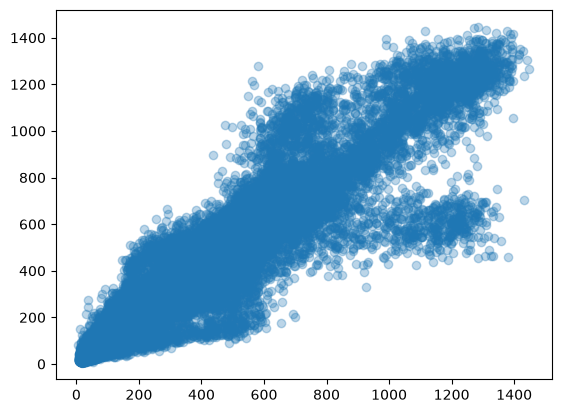

In [11]:
# autocorrelation?
shift = 24*4
t = df["VOLUME"][df["DIRECTION"] == "W"][shift:]
t_minus = df["VOLUME"][df["DIRECTION"] == "W"][:-shift]
plt.scatter(t, t_minus, alpha=0.3)
np.corrcoef(t, t_minus)

In [51]:
# pull the date/month/time info out of the datetime object
def extract_date_features(df):
    # return df[["STUDY_DATE"]].astype(int)
    
    # df["DAY_OF_WEEK"] = df["STUDY_DATE"].dt.day_of_week # mapped Sunday = 0, Saturday = 6
    df["DAY_OF_WEEK_C"] = np.cos(2*np.pi*df["STUDY_DATE"].dt.day_of_week / 7)
    df["DAY_OF_WEEK_S"] = np.sin(2*np.pi*df["STUDY_DATE"].dt.day_of_week / 7)
    # df["DAY_OF_MONTH"] = df["STUDY_DATE"].dt.day
    # df["MONTH"] = df["STUDY_DATE"].dt.month
    # df["TIME_HOUR"] = df["STUDY_DATE"].dt.hour
    
    df["TIME_HOUR_C"] = np.cos(2*np.pi*df["STUDY_DATE"].dt.hour / 24)
    df["TIME_HOUR_S"] = np.sin(2*np.pi*df["STUDY_DATE"].dt.hour / 24)
    # df["TIME_MINUTE"] = df["STUDY_DATE"].dt.minute

    return df.drop(columns="STUDY_DATE")


In [52]:
# plt.scatter(extract_date_features(df), df["VOLUME"])

In [53]:
# try a super basic model
from sklearn.preprocessing import FunctionTransformer
from sklearn.pipeline import make_pipeline
from sklearn.compose import make_column_transformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.model_selection import cross_val_score, TimeSeriesSplit
from sklearn.tree import DecisionTreeRegressor

# hold back the last 20% for testing
threshold = int(0.8 * len(df))
train_val, test = df[:threshold], df[threshold:]

# BIG MISTAKE! Can't randomly split time series data
# train, val = train_test_split(train_val, test_size=0.2, random_state=1234)
threshold = int(0.8 * len(train_val))
train, val = train_val[:threshold], train_val[threshold:]

pipeline = make_pipeline (
        make_column_transformer(
            (OneHotEncoder(drop="if_binary"), ["DIRECTION"]),
            (FunctionTransformer(extract_date_features), ["STUDY_DATE"])
        ),
        DecisionTreeRegressor(),
)

pipeline.fit(train, train["VOLUME"])

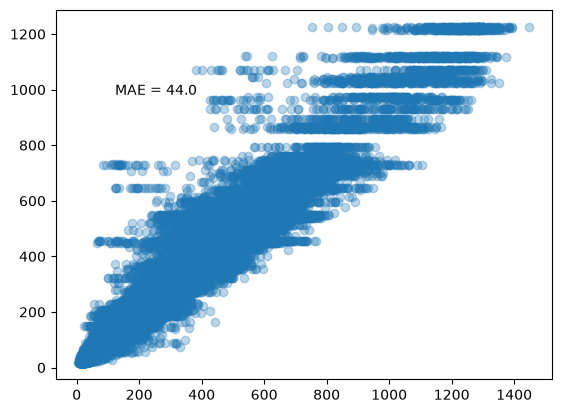

In [54]:
def predict_plot(df):
    y_est = pipeline.predict(df)
    plt.scatter(df["VOLUME"], y_est, alpha=0.3)
    plt.text(0.1 * max(y_est), 0.8*max(y_est), f"MAE = {np.abs(df["VOLUME"] - y_est).mean():.1f}")

predict_plot(train)

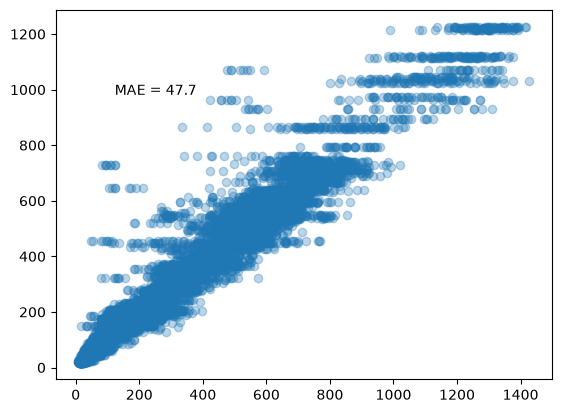

In [55]:
# what about validation data?
predict_plot(val)

In [56]:
# Don't look at test data until the very end
# predict_plot(test)

## Supplemental figures

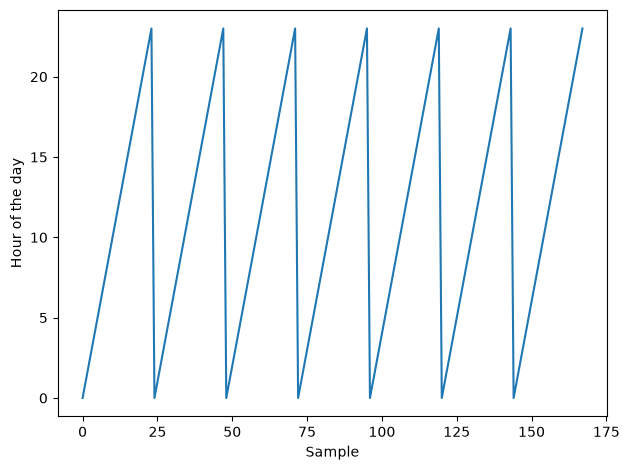

In [57]:
# encoding hours
hours = np.hstack([np.arange(24)]*7)
plt.plot(hours)
plt.xlabel("Sample")
plt.ylabel("Hour of the day")
plt.tight_layout()
# plt.savefig("../../img/12-hours.png")